In [3]:
import pandas as pd

df = pd.read_csv('/Users/hussamdahshan/AI data science/telcom-client-churn-prediction/data/cleaned_telco_customer_churn.csv')

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1936.30,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,107.70,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1903.50,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,141.40,Yes


In [5]:
x = df.iloc[: , 1:-1]

In [6]:
y = df.iloc[: , -1]

In [7]:
y

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: str

In [8]:
#Mapping the 'y' changing the yes and no to 0 and 1

y = y.map({'Yes': 1 , 'No': 0})

In [9]:
# y result after mapping 
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state= 42)

In [32]:
# importing sklearn functions for the model 

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import joblib 
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
# building the Pipeline for both the categorical and numerical data

numerical_cols = x.select_dtypes(['float','int']).columns.tolist()
categorical_cols = x.select_dtypes(['str']).columns.tolist()

In [13]:
numerical_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [14]:
categorical_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [15]:
x.shape

(7043, 19)

In [17]:
# Building the pipeline for the numerical col

numerical_pipeline = Pipeline(
    [
        ('Imputer',SimpleImputer(strategy='mean')),
        ('scaler',StandardScaler())
    ]
)

In [18]:
# Building the pipeline for the categorical col

categorical_pipeline = Pipeline(
    [
        ('Imputer',SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder())
    ]
)

In [21]:
# The transformation step

preprocessor = ColumnTransformer(
    [
        ('num',numerical_pipeline,numerical_cols),
        ('Category',categorical_pipeline,categorical_cols)
    ]
)

In [23]:
log_reg_pipleline = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('log_reg', LogisticRegression())
    ]
)

In [26]:
# the final pipeline takes the raw data and send its to the model pipeline and it takes x_train, y_train

log_reg_pipleline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('log_reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('Category', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remain

In [27]:
# fitting the y predict into the model pipeline with the x_test

y_pred = log_reg_pipleline.predict(X_test)

## Model Evauation

In [35]:
print(classification_report(y_test,y_pred, target_names=['No','Yes']))

              precision    recall  f1-score   support

          No       0.86      0.90      0.88      1036
         Yes       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409



In [30]:
cm = confusion_matrix(y_test,y_pred)

In [31]:
cm

array([[935, 101],
       [151, 222]])

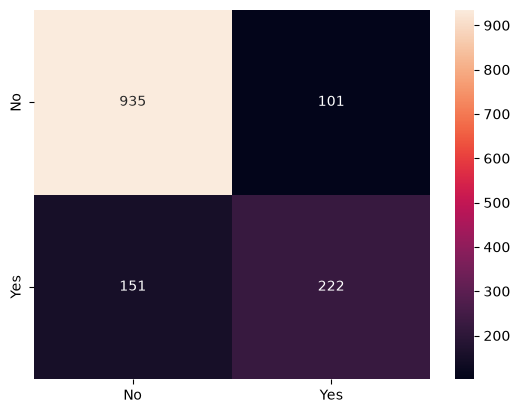

In [34]:
plt.figure()
sns.heatmap(cm, annot=True, fmt ='d', xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.show()

In [39]:
joblib.dump(log_reg_pipleline,'/Users/hussamdahshan/AI data science/telcom-client-churn-prediction/model/log_reg_pipline.joblib')

['/Users/hussamdahshan/AI data science/telcom-client-churn-prediction/model/log_reg_pipline.joblib']